In [ ]:
!pip install pandas matplotlib seaborn

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import auth
auth.authenticate_user()

import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)

In [ ]:
from google.colab import auth
import gspread
from google.auth import default
import pandas as pd
import matplotlib.pyplot as plt

# Authenticate your Google account
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# Open the Spreadsheet by URL
spreadsheet_url = "https://docs.google.com/spreadsheets/d/17cSsi5b1aMQFjjc7PHKgz0oeBlnQ9jiNXKdYWJ4Gjqk/edit?usp=sharing"
ss = gc.open_by_url(spreadsheet_url)

# Load the 3rd sheet (Index 2)
worksheet = ss.get_worksheet(3)
raw_rows = worksheet.get_all_values()

In [ ]:
import pandas as pd

clean_records = []

# List of target personas to filter
target_personas = [
    'man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3',
    'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3'
]

for row in raw_rows:
    # Skip header rows or empty rows
    if not row or row[0] == 'model_name' or row[0] == 'persona_folder' or "Model:" in row[0]:
        continue

    # Check if the second column (persona_folder) is in our targets
    # Note: row[0] is now model_name, row[1] is persona_folder
    if len(row) > 1 and row[1] in target_personas:
        try:
            record = {
                'Model': row[0],
                'Persona': row[1],
                'Accuracy': float(row[4]) if row[4] else 0,
                'Sum_Prompt_Tokens': float(row[8]) if row[8] else 0,
                'Sum_Completion_Tokens': float(row[9]) if row[9] else 0,
                'Sum_Reasoning_Tokens': float(row[10]) if row[10] else 0,
                'Sum_Total_Tokens': float(row[11]) if row[11] else 0,
                'Avg_Prompt_Tokens': float(row[12]) if row[12] else 0,
                'Avg_Completion_Tokens': float(row[13]) if row[13] else 0,
                'Avg_Reasoning_Tokens': float(row[14]) if row[14] else 0,
                'Avg_Total_Tokens': float(row[15]) if row[15] else 0
            }
            clean_records.append(record)
        except (ValueError, IndexError):
            continue

# Create the full DataFrame
df_full = pd.DataFrame(clean_records)

# Verify that all models (DeepSeek, OLMo, Qwen, etc.) are loaded
print(f"Total rows loaded: {len(df_full)}")
display(df_full.head(20))

Total rows loaded: 96


,Model,Persona,Accuracy,Sum_Prompt_Tokens,Sum_Completion_Tokens,Sum_Reasoning_Tokens,Sum_Total_Tokens,Avg_Prompt_Tokens,Avg_Completion_Tokens,Avg_Reasoning_Tokens,Avg_Total_Tokens
0,AllenAI OLMo 3 32B Think,man_explicit_1,0.948400,143427.0,1874173.0,0.0,2017600.0,108.74,1420.90,0.00,1529.64
1,AllenAI OLMo 3 32B Think,man_implicit_1,0.942400,1899143.0,1737234.0,0.0,3636377.0,1439.84,1317.08,0.00,2756.92
2,AllenAI OLMo 3 32B Think,man_implicit_2,0.953800,454727.0,1665697.0,0.0,2120424.0,344.75,1262.85,0.00,1607.60
3,AllenAI OLMo 3 32B Think,man_implicit_3,0.947700,400379.0,1664821.0,0.0,2065200.0,303.55,1262.18,0.00,1565.73
4,AllenAI OLMo 3 32B Think,woman_explicit_1,0.944700,143413.0,1898522.0,0.0,2041935.0,108.73,1439.36,0.00,1548.09
5,AllenAI OLMo 3 32B Think,woman_implicit_1,0.904500,1356464.0,1647800.0,0.0,3004264.0,1028.40,1249.28,0.00,2277.68
6,AllenAI OLMo 3 32B Think,woman_implicit_2,0.908300,407495.0,1472112.0,0.0,1879607.0,308.94,1116.08,0.00,1425.02
7,AllenAI OLMo 3 32B Think,woman_implicit_3,0.934000,329315.0,1566660.0,0.0,1895975.0,249.67,1187.76,0.00,1437.43
8,DeepSeek V3.2,man_explicit_1,0.960576,107757.0,314469.0,2252.0,422226.0,81.70,238.42,1.71,320.19
9,DeepSeek V3.2,man_implicit_1,0.958302,709704.0,299691.0,235.0,1009395.0,538.06,227.21,0.18,765.45


In [ ]:
def get_category_eng(name):
    # Check 'woman' first to avoid incorrect categorization into 'man'
    if 'woman_explicit' in name: return 'Woman Explicit'
    if 'woman_implicit' in name: return 'Woman Implicit (Avg)'
    if 'man_explicit' in name: return 'Man Explicit'
    if 'man_implicit' in name: return 'Man Implicit (Avg)'
    return 'Other'

df_full['Category'] = df_full['Persona'].apply(get_category_eng)

In [ ]:
# Calculate mean for Accuracy
df_summary = df_full.groupby(['Model', 'Category'])['Accuracy'].mean().reset_index()

# Display all rows
pd.set_option('display.max_rows', None) # To display all rows
display(df_summary)

,Model,Category,Accuracy
0,AllenAI OLMo 3 32B Think,Man Explicit,0.948400
1,AllenAI OLMo 3 32B Think,Man Implicit (Avg),0.947967
2,AllenAI OLMo 3 32B Think,Woman Explicit,0.944700
3,AllenAI OLMo 3 32B Think,Woman Implicit (Avg),0.915600
4,DeepSeek V3.2,Man Explicit,0.960576
5,DeepSeek V3.2,Man Implicit (Avg),0.960071
6,DeepSeek V3.2,Woman Explicit,0.955269
7,DeepSeek V3.2,Woman Implicit (Avg),0.960071
8,Google Gemini 2.5 Flash,Man Explicit,0.951478
9,Google Gemini 2.5 Flash,Man Implicit (Avg),0.954511


In [ ]:
# Transform table: Model as rows, Category as columns
df_pivot = df_summary.pivot(index='Model', columns='Category', values='Accuracy')

# Arrange column order for clarity: Man first, then Woman
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']
df_pivot = df_pivot[column_order]

# Display ALL (Ensures all models and categories are shown)
display(df_pivot)

Category,Man Explicit,Man Implicit (Avg),Woman Explicit,Woman Implicit (Avg)
Model,,,,
AllenAI OLMo 3 32B Think,0.948400,0.947967,0.944700,0.915600
DeepSeek V3.2,0.960576,0.960071,0.955269,0.960071
Google Gemini 2.5 Flash,0.951478,0.954511,0.947688,0.958807
Google Gemma 2 9B,0.865800,0.876433,0.880200,0.877667
Google Gemma 3 27B,0.941622,0.947941,0.941622,0.946584
Meta Llama 3.1 8B Instruct,0.827142,0.831691,0.822593,0.836998
Meta Llama 3.3 70B Instruct,0.922669,0.931261,0.916603,0.935810
Mistral Ministral 8B,0.934041,0.930503,0.931766,0.934278
OpenAI GPT-OSS-120B,0.962851,0.963103,0.962851,0.961071


In [ ]:
# 1. Calculate Delta: Difference between Implicit and Explicit performance
df_pivot['Delta Man (Imp-Exp)'] = df_pivot['Man Implicit (Avg)'] - df_pivot['Man Explicit']
df_pivot['Delta Woman (Imp-Exp)'] = df_pivot['Woman Implicit (Avg)'] - df_pivot['Woman Explicit']

# 2. Calculate Gender Gap: Average Man accuracy minus Average Woman accuracy
df_pivot['Gender Gap (Man-Woman)'] = (df_pivot['Man Explicit'] + df_pivot['Man Implicit (Avg)'])/2 - \
                                     (df_pivot['Woman Explicit'] + df_pivot['Woman Implicit (Avg)'])/2

# Display the updated table with Deltas
display(df_pivot)

Category,Man Explicit,Man Implicit (Avg),Woman Explicit,Woman Implicit (Avg),Delta Man (Imp-Exp),Delta Woman (Imp-Exp),Gender Gap (Man-Woman)
Model,,,,,,,
AllenAI OLMo 3 32B Think,0.948400,0.947967,0.944700,0.915600,-0.000433,-0.029100,0.018033
DeepSeek V3.2,0.960576,0.960071,0.955269,0.960071,-0.000505,0.004802,0.002653
Google Gemini 2.5 Flash,0.951478,0.954511,0.947688,0.958807,0.003033,0.011119,-0.000253
Google Gemma 2 9B,0.865800,0.876433,0.880200,0.877667,0.010633,-0.002533,-0.007817
Google Gemma 3 27B,0.941622,0.947941,0.941622,0.946584,0.006319,0.004962,0.000678
Meta Llama 3.1 8B Instruct,0.827142,0.831691,0.822593,0.836998,0.004549,0.014405,-0.000379
Meta Llama 3.3 70B Instruct,0.922669,0.931261,0.916603,0.935810,0.008592,0.019207,0.000759
Mistral Ministral 8B,0.934041,0.930503,0.931766,0.934278,-0.003538,0.002512,-0.000750
OpenAI GPT-OSS-120B,0.962851,0.963103,0.962851,0.961071,0.000252,-0.001780,0.001016


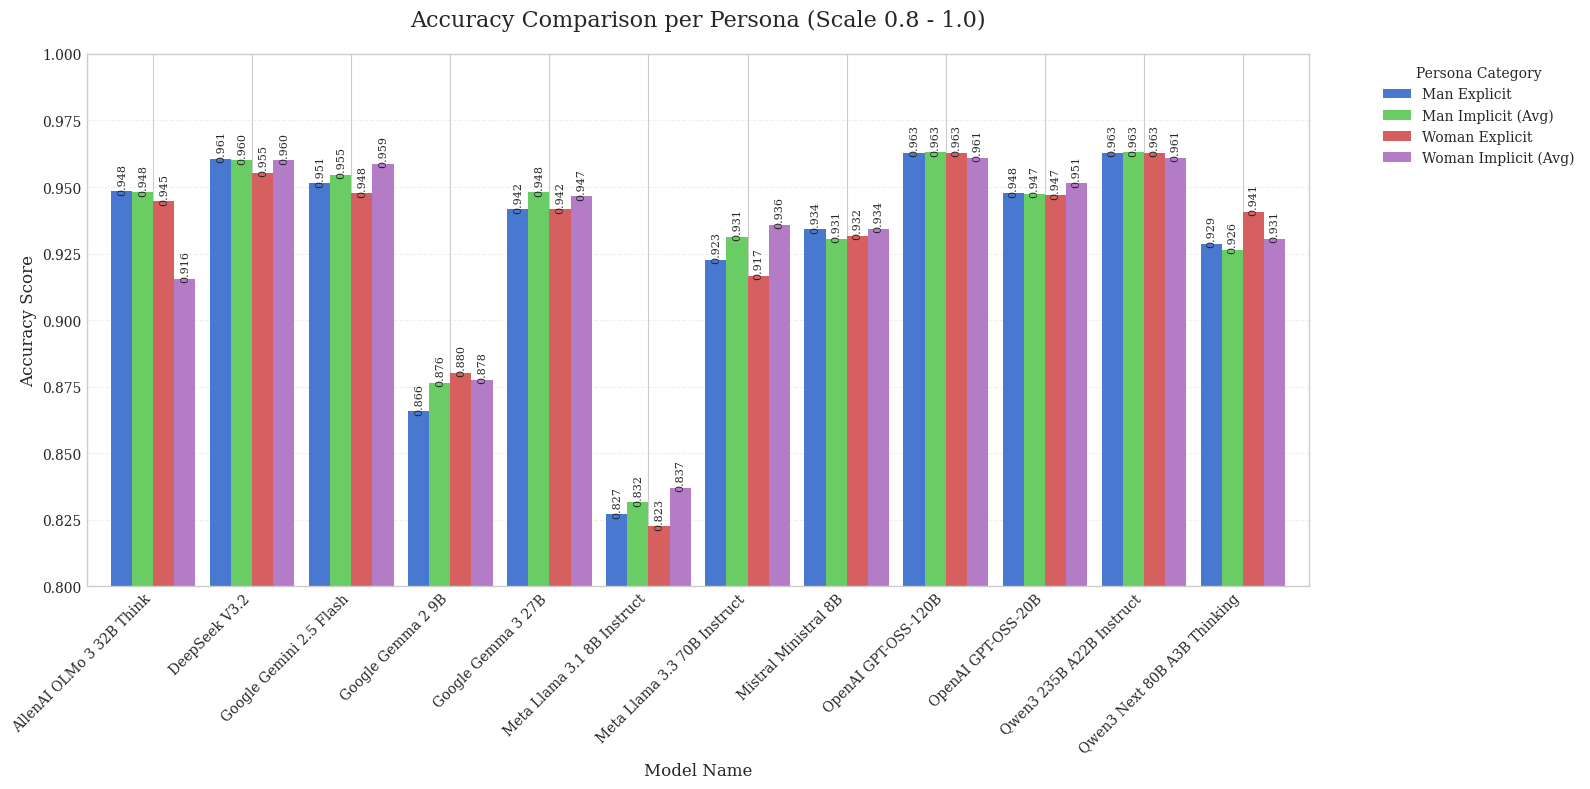

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Use the column order you defined
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Create the plot
ax = df_pivot[column_order].plot(kind='bar', figsize=(16, 8), width=0.85)

# SET SCALE: Range 0.8 to 1.0
plt.ylim(0.8, 1.0)

# ADD NUMBERS: Label on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=8, rotation=90)

# Formatting
plt.title('Accuracy Comparison per Persona (Scale 0.8 - 1.0)', fontsize=16, pad=20)
plt.ylabel('Accuracy Score', fontsize=12)
plt.xlabel('Model Name', fontsize=12)
plt.legend(title='Persona Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

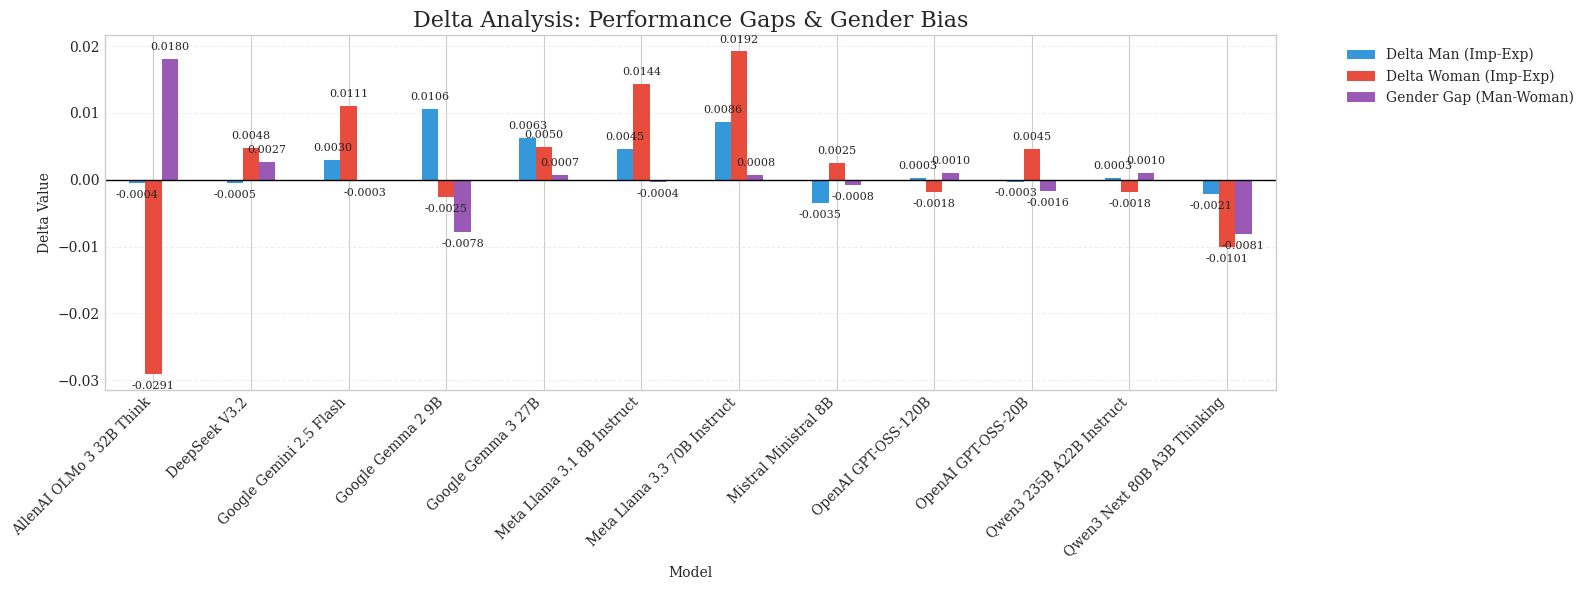

In [ ]:
# Plotting the Deltas
delta_cols = ['Delta Man (Imp-Exp)', 'Delta Woman (Imp-Exp)', 'Gender Gap (Man-Woman)']
ax_delta = df_pivot[delta_cols].plot(kind='bar', figsize=(16, 6), color=['#3498db', '#e74c3c', '#9b59b6'])

plt.axhline(0, color='black', linewidth=1) # Baseline 0

# Add numbers on top/bottom of bars
for p in ax_delta.patches:
    val = p.get_height()
    va = 'bottom' if val > 0 else 'top'
    offset = 5 if val > 0 else -5
    ax_delta.annotate(f'{val:.4f}',
                      (p.get_x() + p.get_width() / 2., val),
                      ha='center', va=va,
                      xytext=(0, offset),
                      textcoords='offset points',
                      fontsize=8)

plt.title('Delta Analysis: Performance Gaps & Gender Bias', fontsize=16)
plt.ylabel('Delta Value')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

This figure presents a **delta analysis** to examine two aspects:

1. The performance gap between **implicit and explicit sentiment**
2. **Gender bias**, represented by performance differences between male and female data

---

### 1. Graph Axes

- **X-axis** shows the list of evaluated **LLM models** (e.g., Llama, Mistral, Gemini, Qwen, etc.).
- **Y-axis** represents the **delta value (Implicit − Explicit)**.

Interpretation:
- **Positive values** indicate that the model performs better on **implicit sentiment**.
- **Negative values** indicate that the model performs better on **explicit sentiment**.

---

### 2. Bar Colors

🔵 **Blue – Delta Man (Implicit − Explicit)**  
Represents the performance difference for **male-related data**.

- Positive values → the model performs better on **implicit sentiment for men**
- Negative values → the model performs better on **explicit sentiment for men**

Example:  
Google Gemma 2 9B = **0.0106**, indicating better performance on **implicit male sentiment**.

---

🔴 **Red – Delta Woman (Implicit − Explicit)**  
Represents the performance difference for **female-related data**.

- Positive values → better performance on **implicit sentiment for women**
- Negative values → better performance on **explicit sentiment for women**

Example:  
Meta Llama 3.3 70B = **0.0192**, indicating strong performance in detecting **implicit female sentiment**.

---

🟣 **Purple – Gender Gap (Man − Woman)**  
This value represents the **difference between male and female performance**.

Formula:

Gender Gap = Delta Man − Delta Woman

Interpretation:

| Value | Meaning |
|------|------|
| Positive | Model performs better for **male data** |
| Negative | Model performs better for **female data** |
| Near zero | **Low bias / relatively fair model** |

Example:  
AllenAI OLMo 3 32B shows a gender gap of **0.018**, indicating that the model performs significantly better for **male data compared to female data**.

---

### 3. Example Interpretation of a Model

**Meta Llama 3.3 70B**

- Delta Man = **0.0086**
- Delta Woman = **0.0192**
- Gender Gap = **0.0008**

This means:
- The model performs better on **implicit sentiment overall**.
- Performance between male and female data is **very similar**.
- The **gender bias is minimal**, suggesting a relatively fair model.

---

### 4. Models with Higher Gender Bias

One noticeable example is **AllenAI OLMo 3 32B**:

- Man = **-0.0004**
- Woman = **-0.0291**
- Gap = **0.018**

This suggests that the model performs **significantly worse on female data**, indicating a larger gender bias.

---

### 5. Models with More Balanced Performance

Models with **gender gap values close to zero** indicate more balanced behavior.  
Examples include:

- DeepSeek V3.2
- Meta Llama 3.3 70B
- Google Gemma 3 27B

These models show **similar performance for male and female data**.

---

### 6. Overall Insights

This analysis reveals that:

1. Many models perform **better on implicit sentiment** compared to explicit sentiment.
2. Some models still exhibit **noticeable gender bias**.
3. Larger and more advanced models, such as **Llama 3.3 70B**, tend to produce **more stable performance with smaller gender gaps**.

---

**In summary**, this figure helps evaluate:
- whether models handle **implicit or explicit sentiment more effectively**, and  
- whether the models exhibit **gender-related bias in sentiment interpretation**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map Size Categories (as per your list)
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–30B)',
    'Google Gemma 3 27B': 'Medium (15B–30B)',
    'AllenAI OLMo 3 32B Think': 'Medium-Large (30B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Add size info to df_pivot (the table you created earlier)
df_delta_size = df_pivot.copy()
df_delta_size['Size_Category'] = df_delta_size.index.map(size_cat_map)

# 3. Calculate Delta per Size Category
# Gender Gap (Man - Woman)
df_delta_size['Gender_Gap'] = (df_delta_size['Man Explicit'] + df_delta_size['Man Implicit (Avg)'])/2 - \
                              (df_delta_size['Woman Explicit'] + df_delta_size['Woman Implicit (Avg)'])/2

# Implicit Gap (Explicit - Implicit)
df_delta_size['Implicit_Gap_Man'] = df_delta_size['Man Explicit'] - df_delta_size['Man Implicit (Avg)']
df_delta_size['Implicit_Gap_Woman'] = df_delta_size['Woman Explicit'] - df_delta_size['Woman Implicit (Avg)']

# Size Order for X-axis
size_order = ['Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
              'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary']

/tmp/ipykernel_707/933353044.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_delta_size, x='Size_Category', y='Gender_Gap', order=size_order, palette='vlag', edgecolor='black')


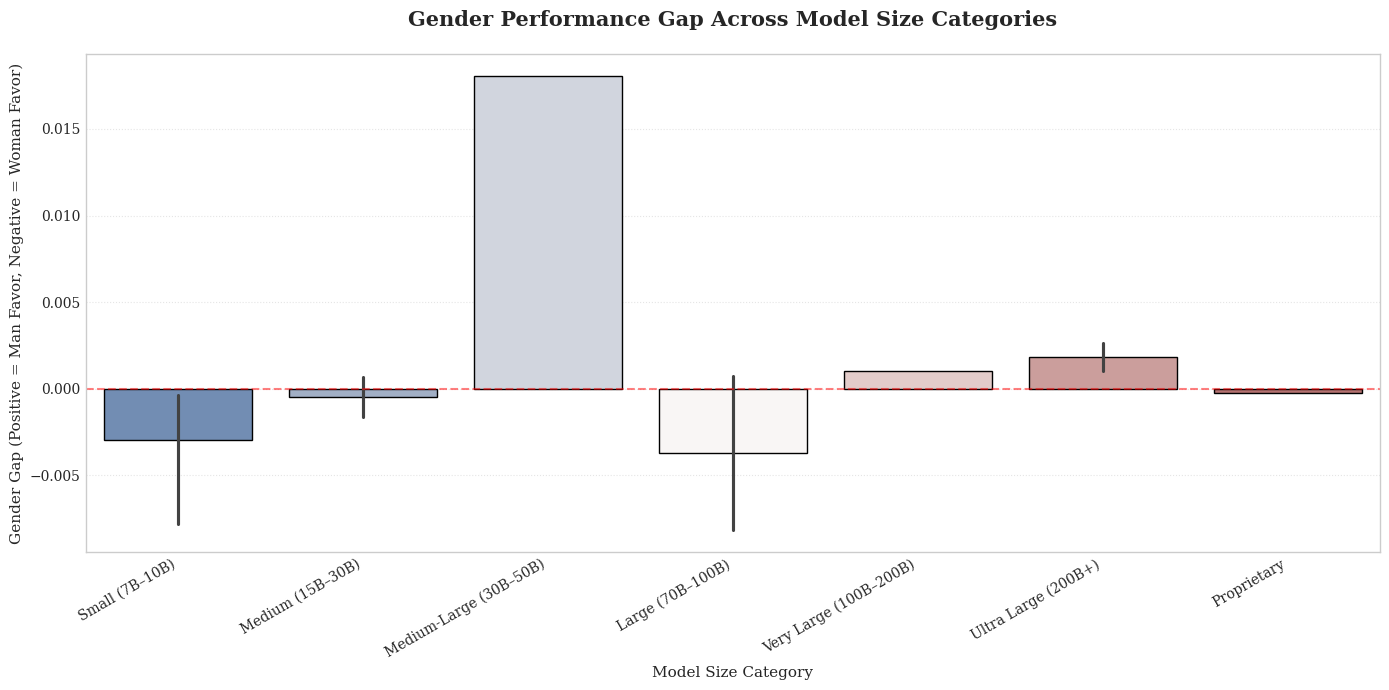

In [ ]:
plt.figure(figsize=(14, 7))
sns.barplot(data=df_delta_size, x='Size_Category', y='Gender_Gap', order=size_order, palette='vlag', edgecolor='black')
plt.axhline(0, color='red', linestyle='--', alpha=0.5) # Ideal line (0 bias)

plt.title('Gender Performance Gap Across Model Size Categories', fontsize=15, fontweight='bold', pad=20)
plt.ylabel('Gender Gap (Positive = Man Favor, Negative = Woman Favor)', fontsize=11)
plt.xlabel('Model Size Category', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mapping Kategori Ukuran sesuai data kamu
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–30B)',
    'Google Gemma 3 27B': 'Medium (15B–30B)',
    'AllenAI OLMo 3 32B Think': 'Medium-Large (30B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Buat DataFrame baru untuk analisis Delta
df_delta_analysis = df_pivot.copy()
df_delta_analysis['Size_Category'] = df_delta_analysis.index.map(size_cat_map)

# 3. HITUNG DELTA (Ini kuncinya agar tidak KeyError)
# Delta Gender: Man - Woman (Rata-rata)
df_delta_analysis['Gender_Gap'] = (df_delta_analysis['Man Explicit'] + df_delta_analysis['Man Implicit (Avg)'])/2 - \
                                  (df_delta_analysis['Woman Explicit'] + df_delta_analysis['Woman Implicit (Avg)'])/2

# Delta Reasoning: Explicit - Implicit (Melihat penurunan performa)
df_delta_analysis['Reasoning_Gap_Man'] = df_delta_analysis['Man Explicit'] - df_delta_analysis['Man Implicit (Avg)']
df_delta_analysis['Reasoning_Gap_Woman'] = df_delta_analysis['Woman Explicit'] - df_delta_analysis['Woman Implicit (Avg)']

# Urutan Ukuran untuk Sumbu X
size_order = ['Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
              'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary']

print("Kolom berhasil dibuat:", df_delta_analysis.columns.tolist())

Kolom berhasil dibuat: ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)', 'Delta Man (Imp-Exp)', 'Delta Woman (Imp-Exp)', 'Gender Gap (Man-Woman)', 'Overall_Avg', 'Size_Category', 'Gender_Gap', 'Reasoning_Gap_Man', 'Reasoning_Gap_Woman']


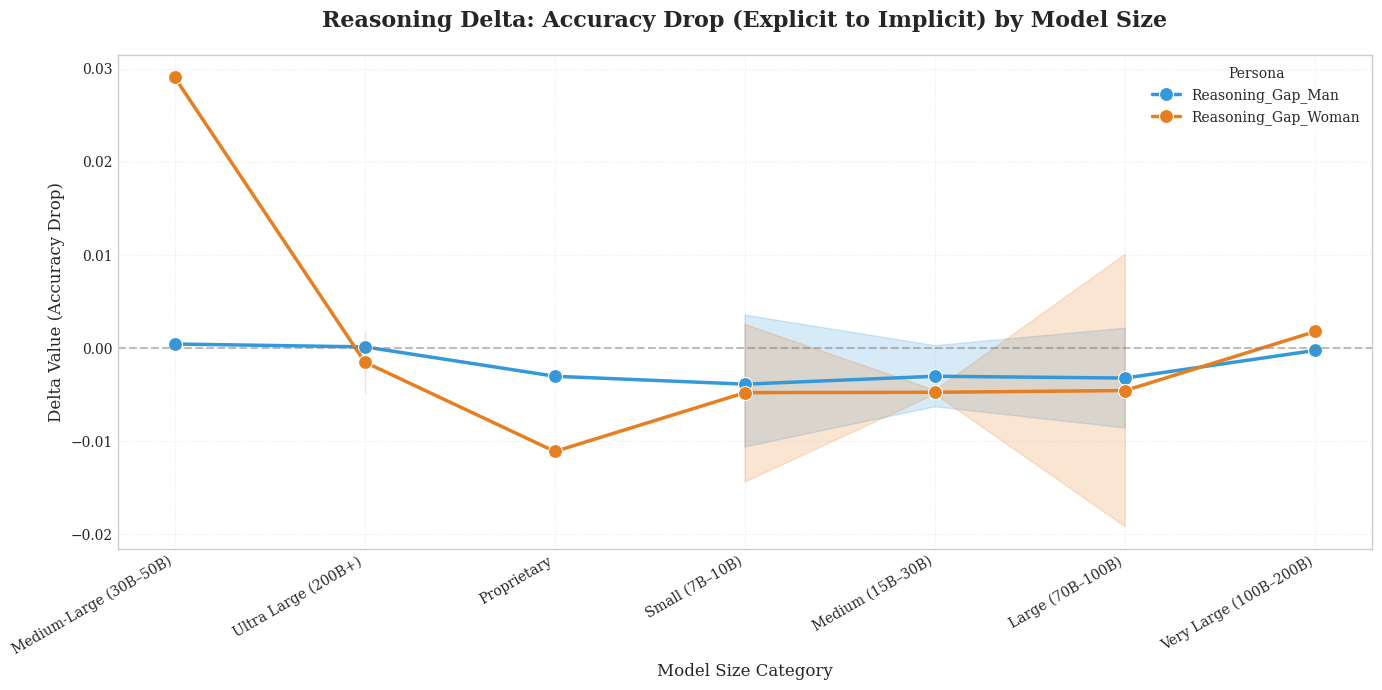

In [ ]:
# Melt data agar bisa di-plot berdampingan
df_melt = df_delta_analysis.reset_index().melt(
    id_vars=['Size_Category'],
    value_vars=['Reasoning_Gap_Man', 'Reasoning_Gap_Woman'],
    var_name='Persona',
    value_name='Gap_Value'
)

plt.figure(figsize=(14, 7), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Line Plot untuk melihat tren berdasarkan ukuran
sns.lineplot(data=df_melt, x='Size_Category', y='Gap_Value', hue='Persona',
             marker='o', markersize=10, linewidth=2.5, palette=['#3498db', '#e67e22'], sort=False)

# Tambahkan garis horizontal di 0 (Ideal: Tidak ada penurunan performa)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

plt.title('Reasoning Delta: Accuracy Drop (Explicit to Implicit) by Model Size', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Delta Value (Accuracy Drop)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

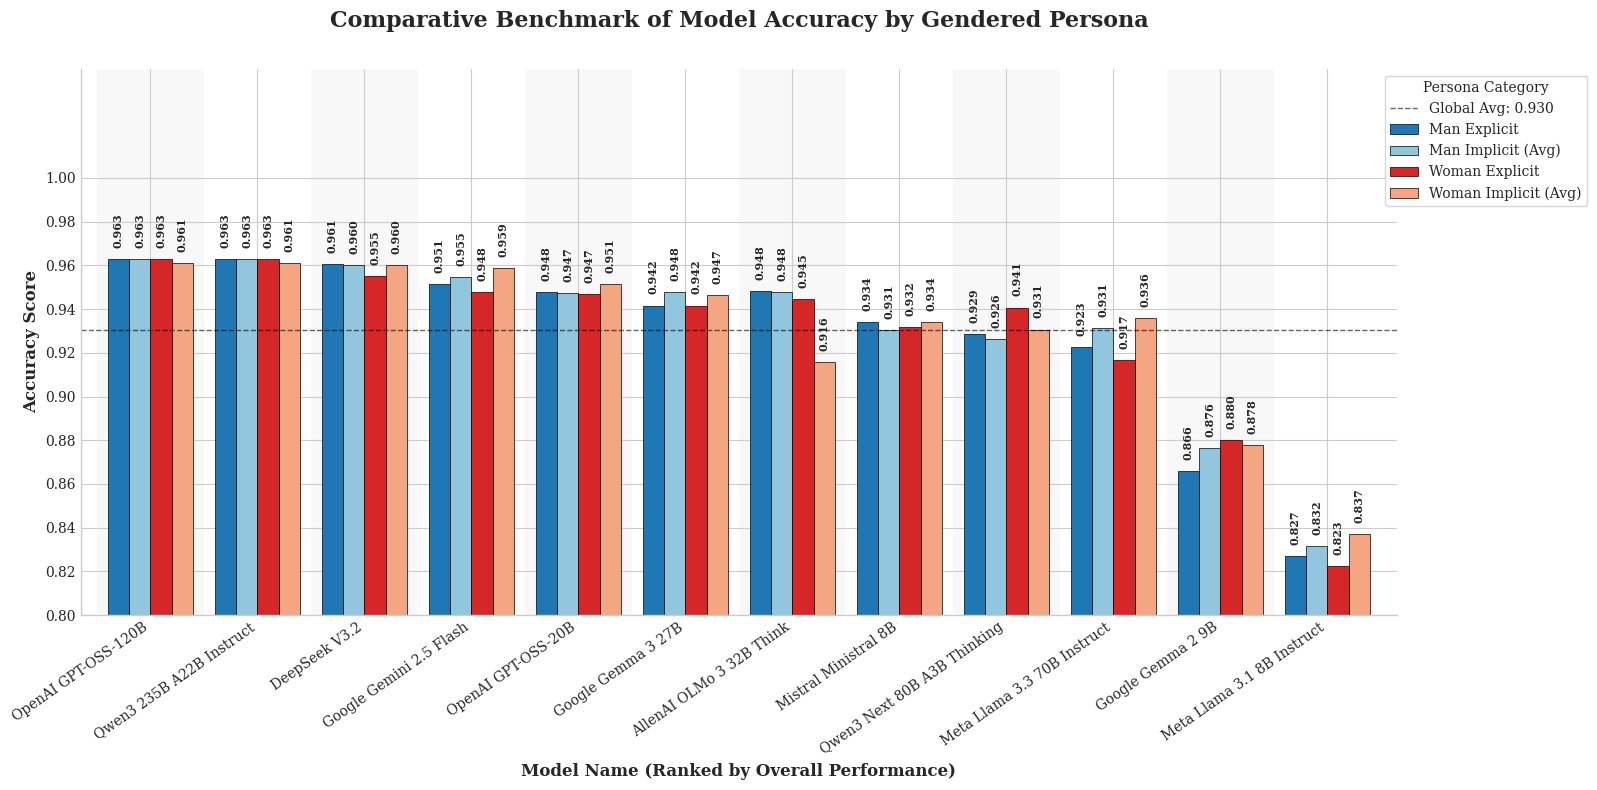

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- PREPARATION ---
# Sorting by overall average to show ranking (Feature 1)
df_pivot['Overall_Avg'] = df_pivot[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1)
df_sorted = df_pivot.sort_values('Overall_Avg', ascending=False)
global_mean = df_sorted['Overall_Avg'].mean()

# --- STYLING SETUP ---
plt.rcParams['font.family'] = 'serif'
colors = ['#1f77b4', '#92c5de', '#d62728', '#f4a582'] # Blue for Men, Red/Orange for Women
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

fig, ax = plt.subplots(figsize=(16, 8), dpi=100)

# --- PLOTTING ---
df_sorted[column_order].plot(kind='bar', ax=ax, width=0.8, color=colors, edgecolor='black', linewidth=0.5)

# --- FEATURE: VERTICAL ANNOTATIONS (90 DEGREES) ---
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 8), # Distance from top of bar
                    textcoords='offset points',
                    fontsize=8,
                    fontweight='bold',
                    rotation=90) # Rotated 90 degrees as requested

# --- FEATURE: ALTERNATING BACKGROUND (FOR READABILITY) ---
# Adds subtle gray stripes behind the bars
for i in range(len(df_sorted)):
    if i % 2 == 0:
        ax.axvspan(i - 0.5, i + 0.5, facecolor='gray', alpha=0.05, zorder=0)

# --- FEATURE: GLOBAL BASELINE ---
ax.axhline(global_mean, color='black', linestyle='--', linewidth=1, alpha=0.6, label=f'Global Avg: {global_mean:.3f}')

# --- COSMETICS ---
ax.set_ylim(0.8, 1.05) # Keep scale focused 0.8 - 1.0
ax.set_title('Comparative Benchmark of Model Accuracy by Gendered Persona', fontsize=16, pad=30, fontweight='bold')
ax.set_ylabel('Accuracy Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Model Name (Ranked by Overall Performance)', fontsize=12, fontweight='bold')

# Clean Spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend Configuration
ax.legend(title='Persona Category', frameon=True, facecolor='white', loc='upper right', bbox_to_anchor=(1.15, 1))

# Ticks
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.yticks(np.arange(0.8, 1.01, 0.02)) # Increments of 0.02 for better precision

plt.tight_layout()
plt.show()

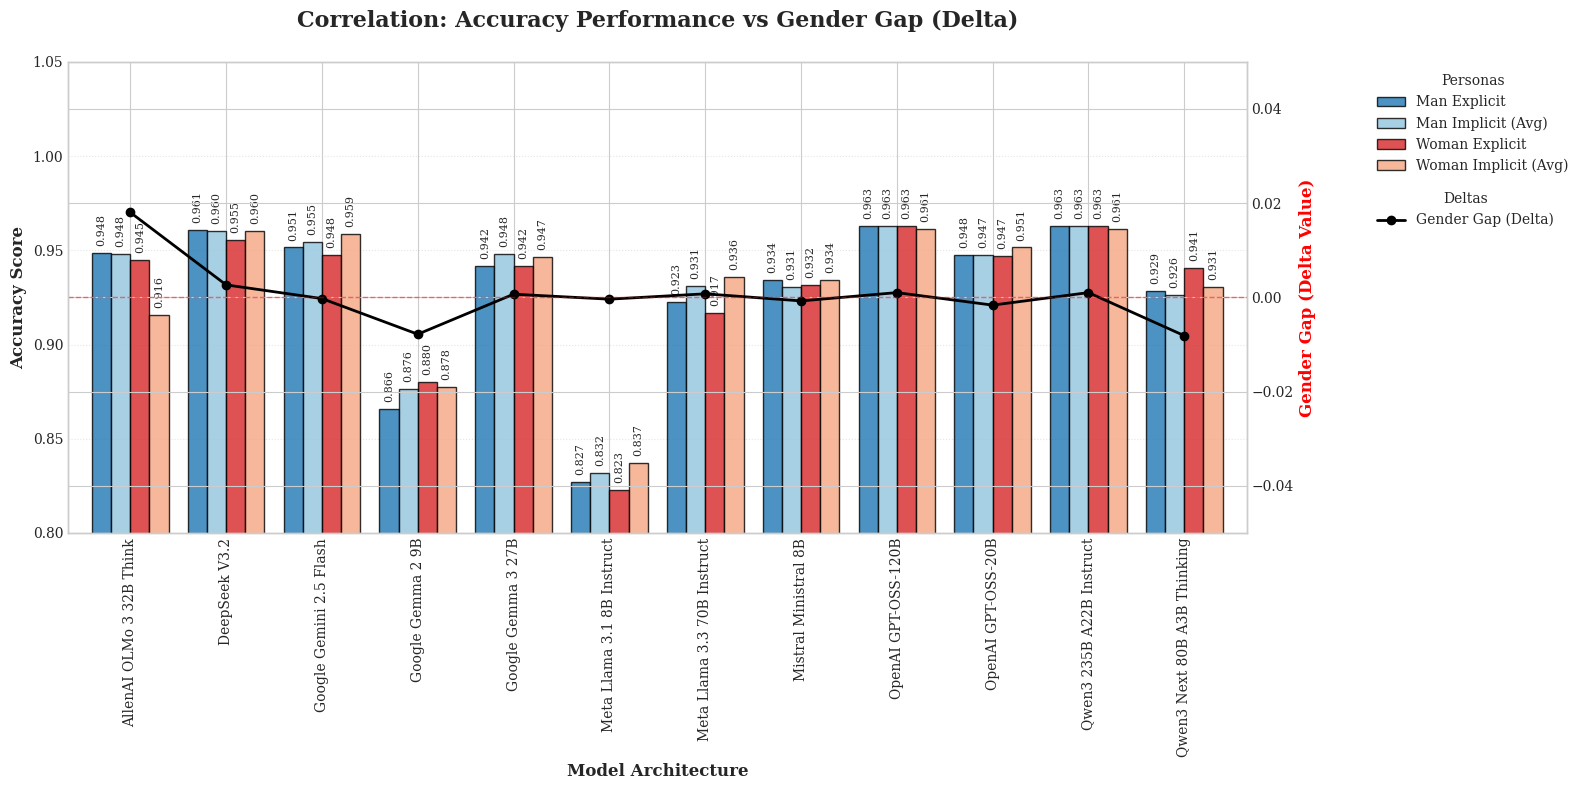

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Ensure Delta is calculated in df_pivot
df_pivot['Gender Gap (Man-Woman)'] = (df_pivot['Man Explicit'] + df_pivot['Man Implicit (Avg)'])/2 - \
                                     (df_pivot['Woman Explicit'] + df_pivot['Woman Implicit (Avg)'])/2

# 2. Plotting Duo-Axis
fig, ax1 = plt.subplots(figsize=(16, 8), dpi=100)
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Bar Chart for Accuracy (Left Y-axis)
colors = ['#1f77b4', '#92c5de', '#d62728', '#f4a582']
df_pivot[column_order].plot(kind='bar', ax=ax1, width=0.8, color=colors, edgecolor='black', alpha=0.8)

ax1.set_ylim(0.8, 1.05) # Focused accuracy scale
ax1.set_ylabel('Accuracy Score', fontsize=12, fontweight='bold')
ax1.set_xlabel('Model Architecture', fontsize=12, fontweight='bold')

# Rotate accuracy numbers 90 degrees
for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontsize=8, rotation=90)

# 3. Line Chart for Delta (Right Y-axis)
ax2 = ax1.twinx() # Create a second Y-axis
ax2.plot(df_pivot.index, df_pivot['Gender Gap (Man-Woman)'], color='black', marker='o',
         linestyle='-', linewidth=2, label='Gender Gap (Delta)')

# Baseline 0 for Delta (Ideally Delta is 0)
ax2.axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.5)

ax2.set_ylabel('Gender Gap (Delta Value)', fontsize=12, color='red', fontweight='bold')
ax2.set_ylim(-0.05, 0.05) # Delta is usually small, so we narrow the scale

# 4. Final Formatting
plt.title('Correlation: Accuracy Performance vs Gender Gap (Delta)', fontsize=16, pad=25, fontweight='bold')
ax1.legend(loc='upper left', bbox_to_anchor=(1.1, 1), title="Personas")
ax2.legend(loc='upper left', bbox_to_anchor=(1.1, 0.75), title="Deltas")

plt.xticks(rotation=45, ha='right')
ax1.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## Token Usage

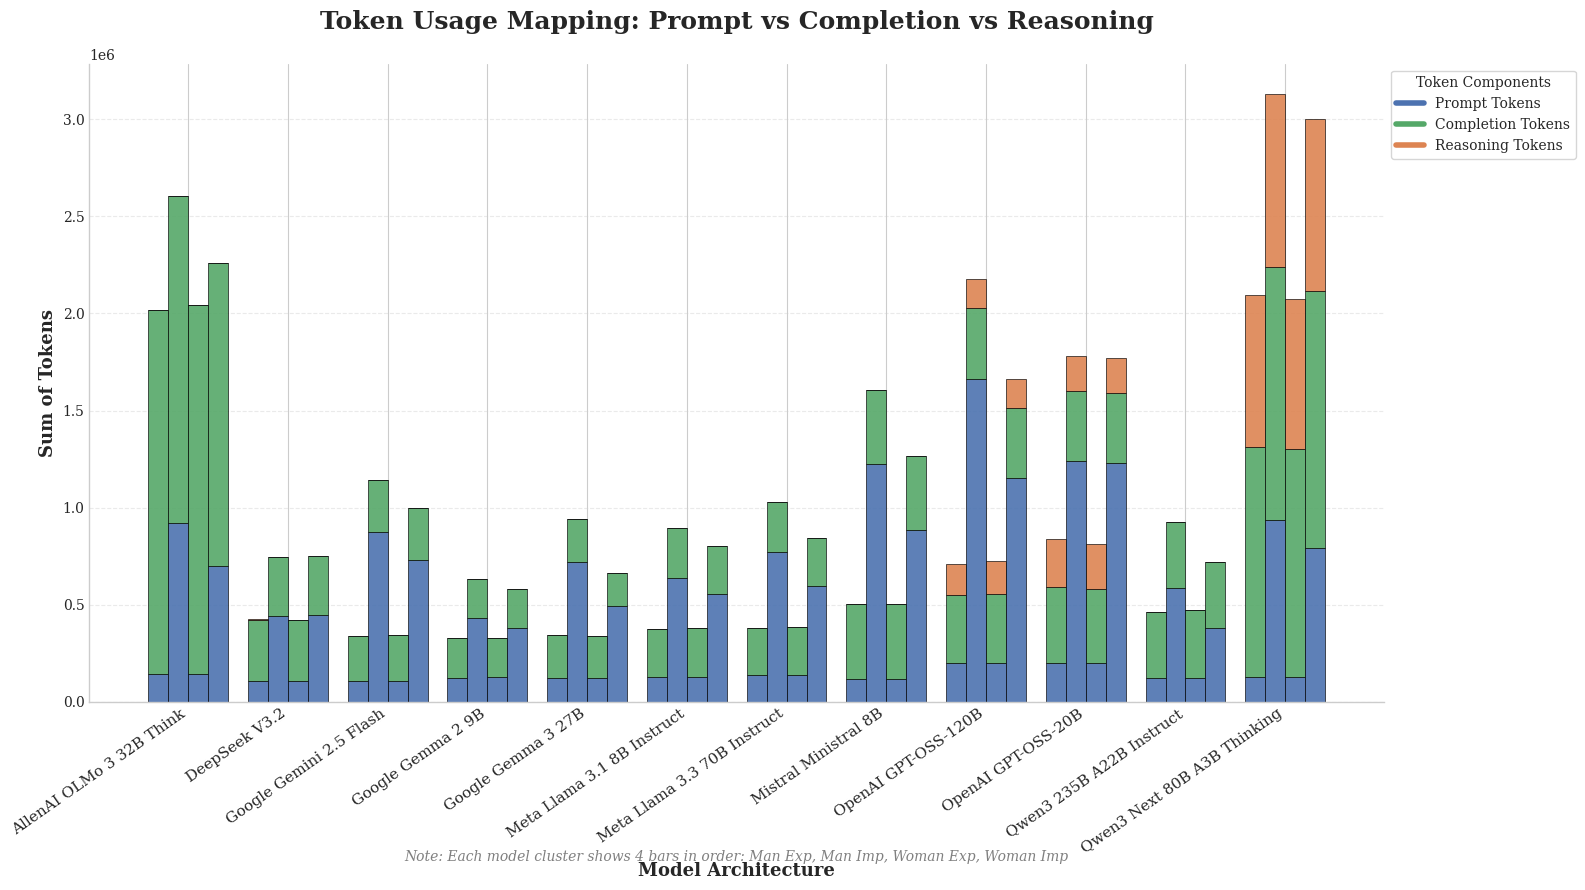

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Helper function for categorization (checking 'woman' first)
def get_category_eng(name):
    if 'woman_explicit' in name: return 'Woman Explicit'
    if 'woman_implicit' in name: return 'Woman Implicit (Avg)'
    if 'man_explicit' in name: return 'Man Explicit'
    if 'man_implicit' in name: return 'Man Implicit (Avg)'
    return 'Other'

# Apply category to your df_full
df_full['Category'] = df_full['Persona'].apply(get_category_eng)

# 2. Calculate Mean for Token Components
token_cols = ['Sum_Prompt_Tokens', 'Sum_Completion_Tokens', 'Sum_Reasoning_Tokens']
df_token_avg = df_full.groupby(['Model', 'Category'])[token_cols].mean().reset_index()

# 3. Setup for Visualization
# We will focus on 'Total Tokens' mapping for each model and category
df_token_avg['Total_Calc'] = df_token_avg[token_cols].sum(axis=1)

# Sort models by total token usage (optional, or use your existing rank)
models = df_token_avg['Model'].unique()
categories = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Professional Colors (Muted palette for papers)
# Prompt = Blue, Completion = Green, Reasoning = Orange
colors = ['#4C72B0', '#55A868', '#DD8452']

# 4. Create the Plot
fig, ax = plt.subplots(figsize=(16, 9), dpi=100)

# We need to calculate positions for grouped bars
x = np.arange(len(models))
width = 0.2  # width of each bar

for i, cat in enumerate(categories):
    # Filter data for this category
    cat_data = df_token_avg[df_token_avg['Category'] == cat].set_index('Model').reindex(models).fillna(0)

    pos = x + (i - 1.5) * width

    # Bottom for stacking
    bottom_val = np.zeros(len(models))

    for j, col in enumerate(token_cols):
        ax.bar(pos, cat_data[col], width, bottom=bottom_val,
               label=col.replace('Sum_', '').replace('_Tokens', '') if i == 0 else "",
               color=colors[j], edgecolor='black', linewidth=0.5, alpha=0.9)
        bottom_val += cat_data[col].values

# 5. Styling & Professionalism
ax.set_title('Token Usage Mapping: Prompt vs Completion vs Reasoning', fontsize=18, fontweight='bold', pad=25)
ax.set_ylabel('Sum of Tokens', fontsize=13, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=13, fontweight='bold')

# X-axis handling
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha='right', fontsize=11)

# Legend (Grouped to avoid duplication)
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], color=colors[0], lw=4, label='Prompt Tokens'),
                   Line2D([0], [0], color=colors[1], lw=4, label='Completion Tokens'),
                   Line2D([0], [0], color=colors[2], lw=4, label='Reasoning Tokens')]
ax.legend(handles=legend_elements, title='Token Components', frameon=True, loc='upper left', bbox_to_anchor=(1, 1))

# Annotation for Persona Groups (Helper text)
ax.text(0.5, -0.25, 'Note: Each model cluster shows 4 bars in order: Man Exp, Man Imp, Woman Exp, Woman Imp',
        transform=ax.transAxes, ha='center', fontsize=10, style='italic', color='gray')

# Remove top/right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

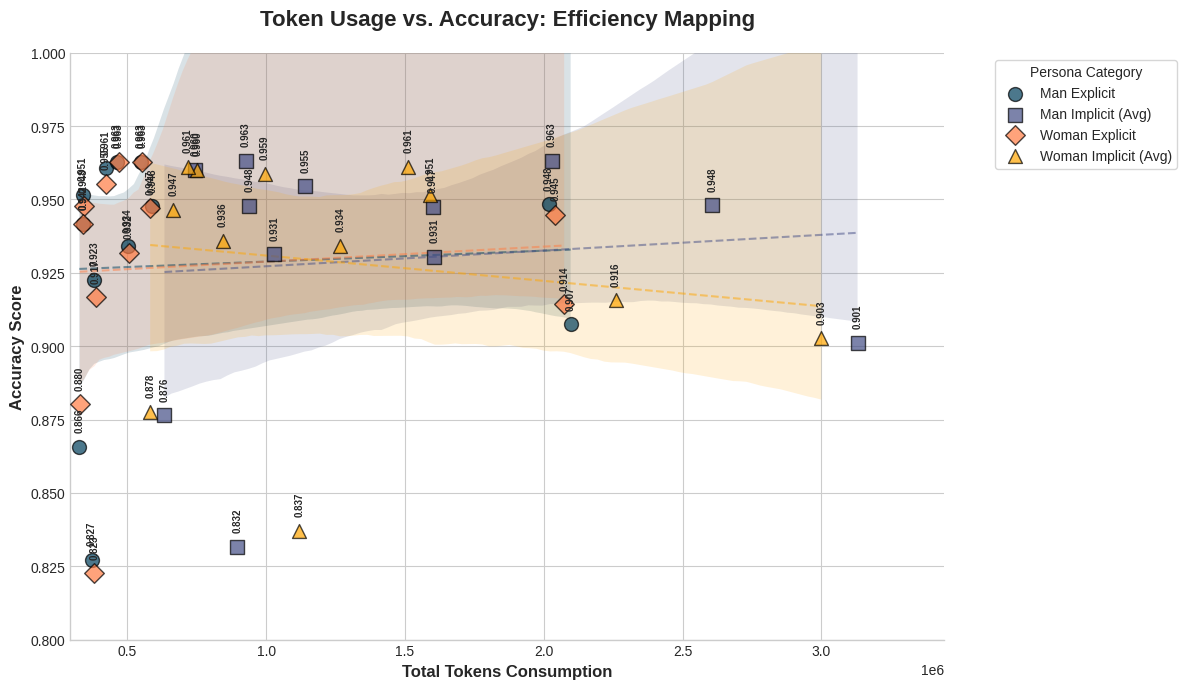

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Average Accuracy and Tokens per Group (Clean Data)
df_influence = df_full.groupby(['Model', 'Category'])[['Accuracy', 'Sum_Total_Tokens']].mean().reset_index()

# 2. Journal-style Plot Setup (Clean & High Contrast)
plt.rcParams['font.family'] = 'serif'
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 7), dpi=100)

# Categories and Colors
# Explicit uses solid colors, Implicit uses lighter/transparent colors
categories = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']
colors = ['#003f5c', '#444e86', '#ff7c43', '#ffa600']
markers = ['o', 's', 'D', '^']

# 3. Plot Scatter with Trend per Category
for i, cat in enumerate(categories):
    subset = df_influence[df_influence['Category'] == cat]

    # Plot data points
    ax.scatter(subset['Sum_Total_Tokens'], subset['Accuracy'],
               s=100, color=colors[i], label=cat, marker=markers[i],
               edgecolor='black', alpha=0.7, zorder=3)

    # Add Thin Trend Line for each category
    if len(subset) > 1:
        sns.regplot(data=subset, x='Sum_Total_Tokens', y='Accuracy',
                    scatter=False, ax=ax, color=colors[i],
                    line_kws={'linestyle':'--', 'linewidth':1.5, 'alpha':0.5})

# 4. Focus Scale (Crucial to avoid clutter)
ax.set_ylim(0.8, 1.0) # As per previous request
ax.set_xlim(df_influence['Sum_Total_Tokens'].min() * 0.9, df_influence['Sum_Total_Tokens'].max() * 1.1)

# 5. 90-Degree Labeling (Only for best model in each category to avoid overlap)
# Or if you want all, use a smaller font
for i in range(len(df_influence)):
    ax.annotate(f"{df_influence['Accuracy'].iat[i]:.3f}",
                (df_influence['Sum_Total_Tokens'].iat[i], df_influence['Accuracy'].iat[i]),
                xytext=(0, 12), textcoords='offset points',
                ha='center', fontsize=7, fontweight='bold', rotation=90)

# 6. Minimalist Formatting
ax.set_title('Token Usage vs. Accuracy: Efficiency Mapping', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Total Tokens Consumption', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy Score', fontsize=12, fontweight='bold')

# Legend outside to keep the graph clean
ax.legend(title='Persona Category', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## Model Size

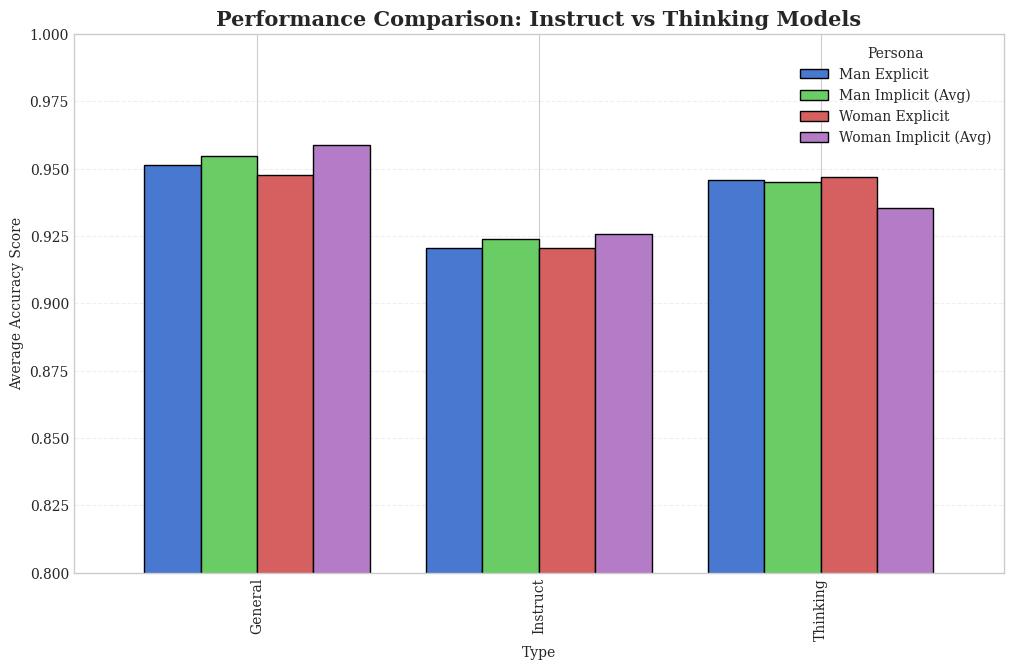

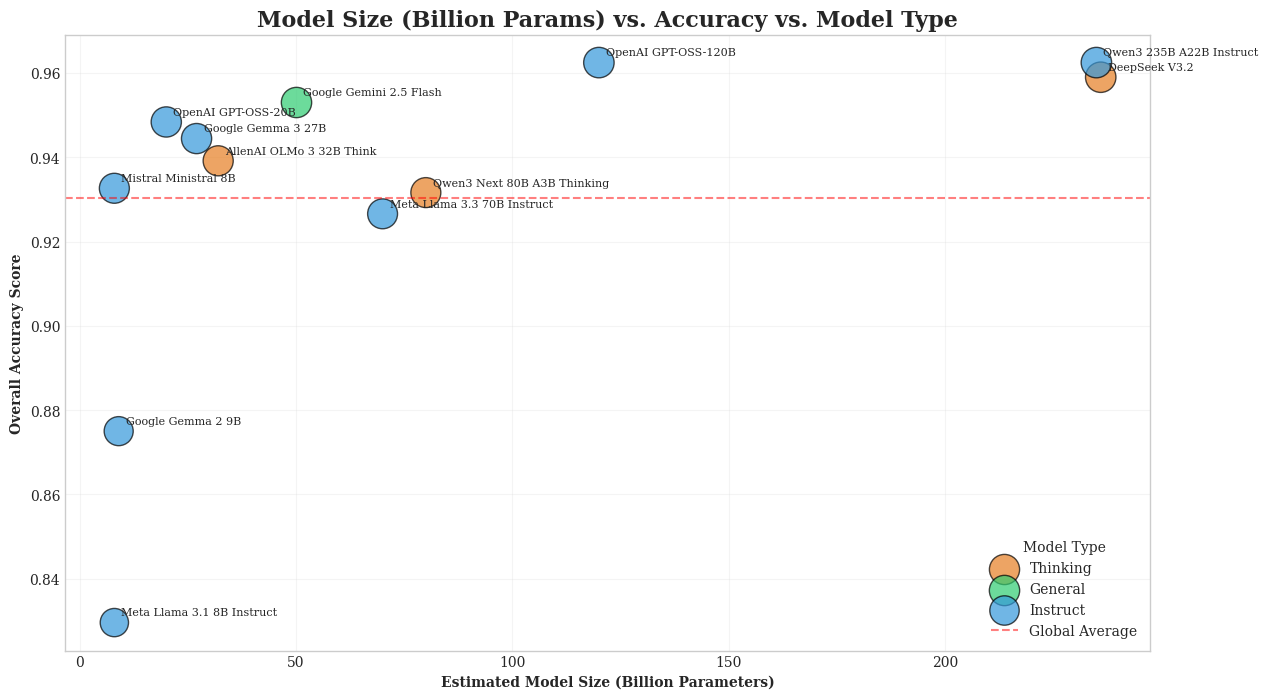

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Map Size and Type data to df_pivot
size_mapping = {
    'OpenAI GPT-OSS-20B': {'Size': 20, 'Category': 'Medium', 'Type': 'Instruct'},
    'Qwen3 Next 80B A3B Thinking': {'Size': 80, 'Category': 'Large', 'Type': 'Thinking'},
    'Qwen3 235B A22B Instruct': {'Size': 235, 'Category': 'Ultra Large', 'Type': 'Instruct'},
    'OpenAI GPT-OSS-120B': {'Size': 120, 'Category': 'Very Large', 'Type': 'Instruct'},
    'Meta Llama 3.3 70B Instruct': {'Size': 70, 'Category': 'Large', 'Type': 'Instruct'},
    'Google Gemma 3 27B': {'Size': 27, 'Category': 'Medium', 'Type': 'Instruct'},
    'Google Gemma 2 9B': {'Size': 9, 'Category': 'Small', 'Type': 'Instruct'},
    'DeepSeek V3.2': {'Size': 236, 'Category': 'Ultra Large', 'Type': 'Thinking'},
    'Google Gemini 2.5 Flash': {'Size': 50, 'Category': 'Proprietary', 'Type': 'General'}, # Est size
    'Meta Llama 3.1 8B Instruct': {'Size': 8, 'Category': 'Small', 'Type': 'Instruct'},
    'Mistral Ministral 8B': {'Size': 8, 'Category': 'Small', 'Type': 'Instruct'},
    'AllenAI OLMo 3 32B Think': {'Size': 32, 'Category': 'Medium-Large', 'Type': 'Thinking'}
}

# Add info to df_pivot
df_plot_size = df_pivot.copy()
df_plot_size['Size_Num'] = df_plot_size.index.map(lambda x: size_mapping.get(x, {}).get('Size', 0))
df_plot_size['Type'] = df_plot_size.index.map(lambda x: size_mapping.get(x, {}).get('Type', 'Unknown'))
df_plot_size['Overall_Acc'] = df_plot_size[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1)

# 2. Visualize by MODEL TYPE (Instruct vs Thinking)
plt.style.use('seaborn-v0_8-muted')
fig, ax = plt.subplots(figsize=(12, 7))

# Group by Type and calculate mean of all 4 personas
df_type = df_plot_size.groupby('Type')[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean()

df_type.plot(kind='bar', ax=ax, width=0.8, edgecolor='black')

plt.title('Performance Comparison: Instruct vs Thinking Models', fontsize=15, fontweight='bold')
plt.ylabel('Average Accuracy Score')
plt.ylim(0.8, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.legend(title='Persona', bbox_to_anchor=(1, 1))
plt.show()

# 3. BUBBLE CHART Visualization (Size vs Accuracy vs Type)
fig, ax = plt.subplots(figsize=(14, 8))

# Define colors for types
type_colors = {'Instruct': '#3498db', 'Thinking': '#e67e22', 'General': '#2ecc71', 'Unknown': '#95a5a6'}

for m_type in df_plot_size['Type'].unique():
    subset = df_plot_size[df_plot_size['Type'] == m_type]
    ax.scatter(subset['Size_Num'], subset['Overall_Acc'],
               s=subset['Overall_Acc']*500, # Bubble size
               label=m_type, color=type_colors.get(m_type, 'gray'),
               alpha=0.7, edgecolors='black')

# Annotate model names
for i, txt in enumerate(df_plot_size.index):
    ax.annotate(txt, (df_plot_size['Size_Num'].iat[i], df_plot_size['Overall_Acc'].iat[i]),
                fontsize=8, xytext=(5,5), textcoords='offset points')

plt.axhline(df_plot_size['Overall_Acc'].mean(), color='red', linestyle='--', alpha=0.5, label='Global Average')
plt.title('Model Size (Billion Params) vs. Accuracy vs. Model Type', fontsize=16, fontweight='bold')
plt.xlabel('Estimated Model Size (Billion Parameters)', fontweight='bold')
plt.ylabel('Overall Accuracy Score', fontweight='bold')
plt.legend(title='Model Type')
plt.grid(True, alpha=0.2)
plt.show()

In [ ]:
# 1. Ensure model type mapping exists
type_map = {
    'AllenAI OLMo 3 32B Think': 'Thinking',
    'DeepSeek V3.2': 'Thinking',
    'Qwen3 Next 80B A3B Thinking': 'Thinking',
    'OpenAI GPT-OSS-20B': 'Instruct',
    'OpenAI GPT-OSS-120B': 'Instruct',
    'Qwen3 235B A22B Instruct': 'Instruct',
    'Meta Llama 3.3 70B Instruct': 'Instruct',
    'Meta Llama 3.1 8B Instruct': 'Instruct',
    'Google Gemma 3 27B': 'Instruct',
    'Google Gemma 2 9B': 'Instruct',
    'Mistral Ministral 8B': 'Instruct',
    'Google Gemini 2.5 Flash': 'General'
}

# 2. Create token summary per model
df_tokens_summary = df_full.groupby('Model')['Sum_Total_Tokens'].mean().reset_index()

# 3. Add Type info
df_tokens_summary['Model_Type'] = df_tokens_summary['Model'].map(type_map)

# 4. Get average Accuracy from the previously created df_pivot
df_tokens_summary = df_tokens_summary.set_index('Model')
df_tokens_summary['Avg_Accuracy'] = df_pivot[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1)

# Check the results
display(df_tokens_summary.head())

,Sum_Total_Tokens,Model_Type,Avg_Accuracy
Model,,,
AllenAI OLMo 3 32B Think,2332672.750,Thinking,0.939167
DeepSeek V3.2,666583.875,Thinking,0.958997
Google Gemini 2.5 Flash,886163.125,General,0.953121
Google Gemma 2 9B,537618.750,Instruct,0.875025
Google Gemma 3 27B,686877.625,Instruct,0.944442


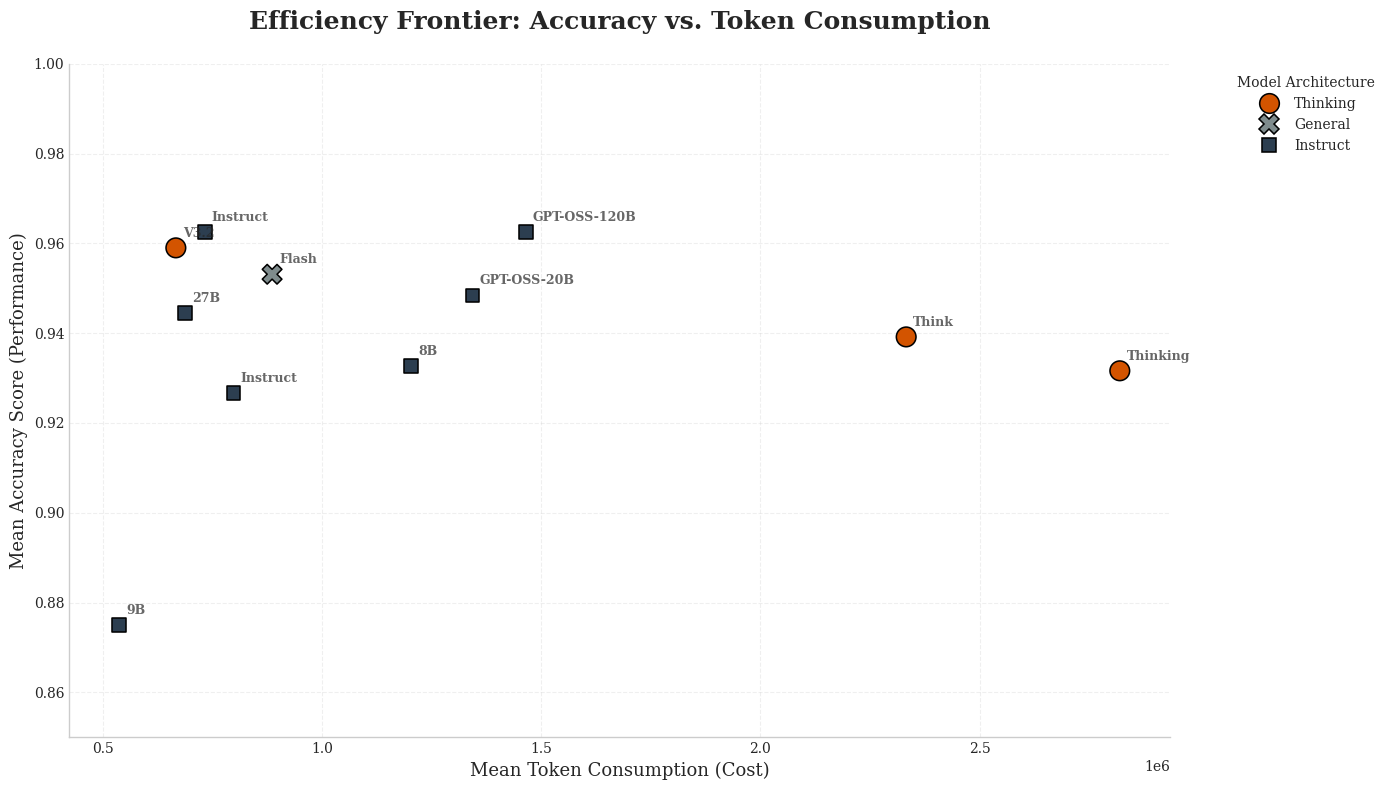

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(14, 8), dpi=100)

# Professional colors
palette = {'Instruct': '#2c3e50', 'Thinking': '#d35400', 'General': '#7f8c8d'}

# Plot Scatter
sns.scatterplot(
    data=df_tokens_summary,
    x='Sum_Total_Tokens',
    y='Avg_Accuracy',
    hue='Model_Type',
    style='Model_Type',
    palette=palette,
    s=200,
    edgecolor='black',
    ax=ax,
    zorder=3
)

# Add model name labels
for i in range(len(df_tokens_summary)):
    ax.annotate(
        df_tokens_summary.index[i].split(' ')[-1], # Take the last word for brevity
        (df_tokens_summary['Sum_Total_Tokens'].iat[i], df_tokens_summary['Avg_Accuracy'].iat[i]),
        xytext=(5, 8), textcoords='offset points',
        fontsize=9, fontweight='bold', alpha=0.7
    )

# Journal-style Formatting
ax.set_ylim(0.85, 1.0) # Focus on high accuracy
ax.set_title('Efficiency Frontier: Accuracy vs. Token Consumption', fontsize=18, pad=25, fontweight='bold')
ax.set_xlabel('Mean Token Consumption (Cost)', fontsize=13)
ax.set_ylabel('Mean Accuracy Score (Performance)', fontsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.3)

plt.legend(title='Model Architecture', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# 1. Calculate Mean and Std from raw data
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# 2. Pivot for Mean (Accuracy)
df_mean = df_stats.pivot(index='Model', columns='Category', values='mean')

# 3. Pivot for Standard Deviation
df_std = df_stats.pivot(index='Model', columns='Category', values='std')

# Arrange column order (ensure category names match previous definitions)
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']
df_mean = df_mean[column_order]
df_std = df_std[column_order]

# Check for NaNs (usually when data has only 1 row, std becomes NaN)
df_std = df_std.fillna(0)

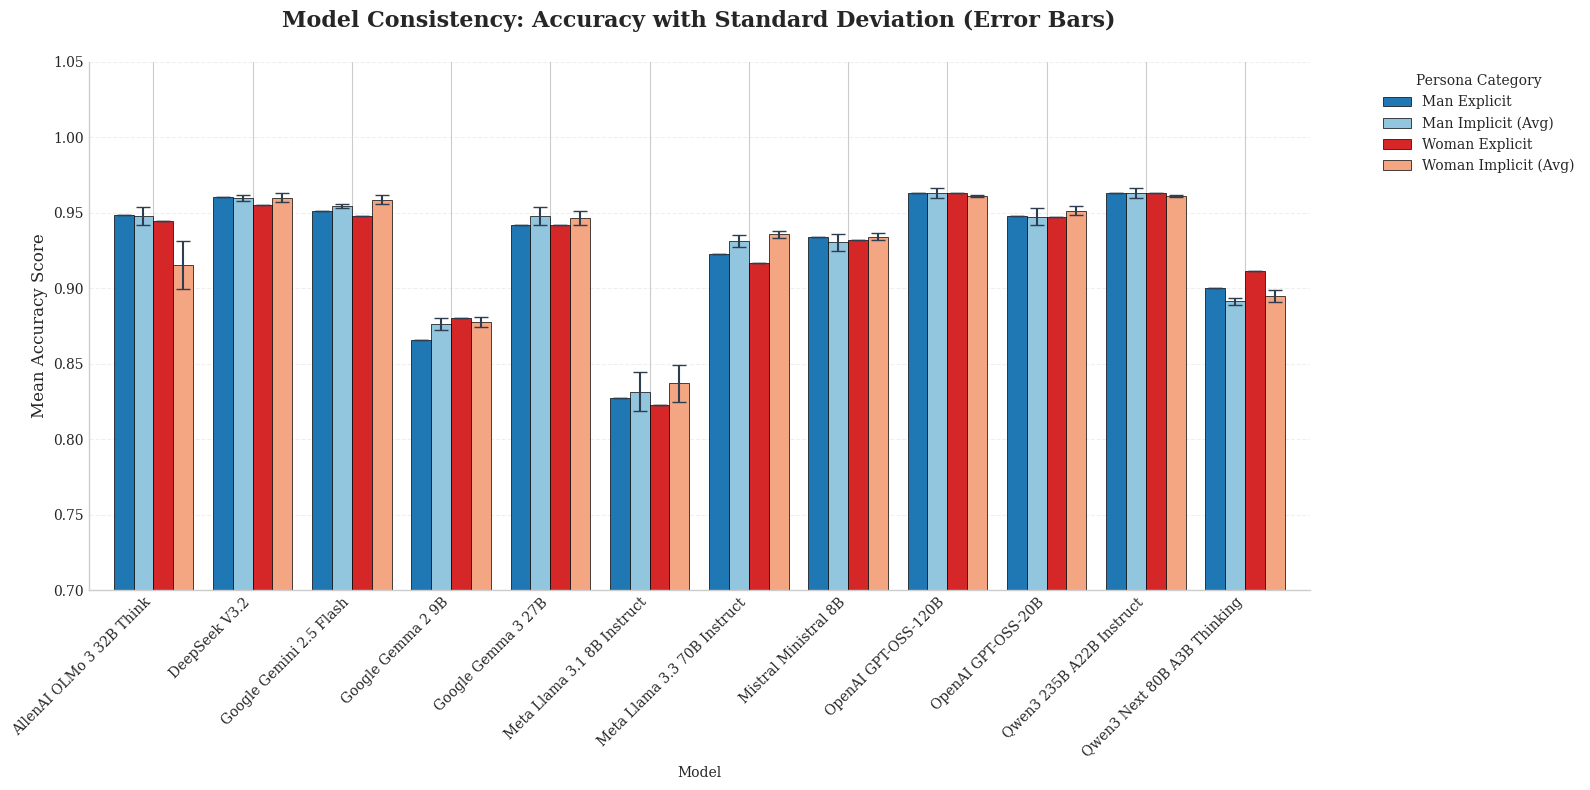

In [ ]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(16, 8), dpi=100)

# Professional colors
colors = ['#1f77b4', '#92c5de', '#d62728', '#f4a582']

# Plot Bar with Error Bars
df_mean.plot(kind='bar', ax=ax, width=0.8, color=colors,
             edgecolor='black', linewidth=0.5,
             yerr=df_std, capsize=5,
             error_kw={'elinewidth':1.5, 'ecolor':'#2c3e50'})

# Focus Scale
ax.set_ylim(0.7, 1.05)
ax.set_title('Model Consistency: Accuracy with Standard Deviation (Error Bars)', fontsize=16, fontweight='bold', pad=25)
ax.set_ylabel('Mean Accuracy Score', fontsize=12)

# Grid and Spines
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=45, ha='right')
plt.legend(title='Persona Category', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
# 1. Ensure df_stats exists (result of groupby Mean & Std)
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# 2. Filter only for Implicit categories
implicit_categories = ['Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_implicit_stats = df_stats[df_stats['Category'].isin(implicit_categories)]

# 3. Re-pivot
df_mean_imp = df_implicit_stats.pivot(index='Model', columns='Category', values='mean')
df_std_imp = df_implicit_stats.pivot(index='Model', columns='Category', values='std').fillna(0)

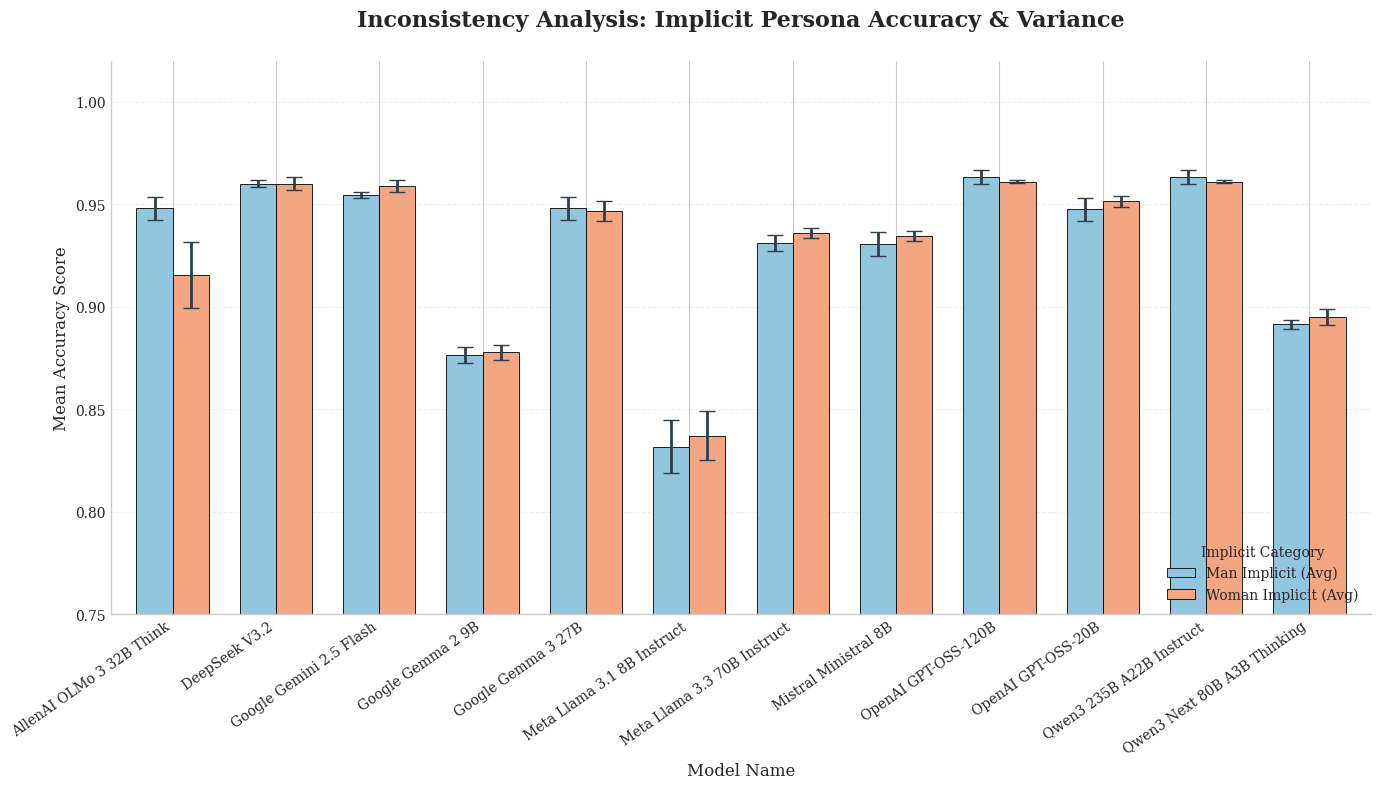

In [ ]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(14, 8), dpi=100)

# Colors: Light Blue vs Light Orange (Implicit specific)
colors_imp = ['#92c5de', '#f4a582']

# Plot Bar with Error Bars
df_mean_imp.plot(kind='bar', ax=ax, width=0.7, color=colors_imp,
                 edgecolor='black', linewidth=0.6,
                 yerr=df_std_imp, capsize=6,
                 error_kw={'elinewidth':2, 'ecolor':'#2c3e50'})

# Set Scale (Focus on variance area)
ax.set_ylim(0.75, 1.02)

ax.set_title('Inconsistency Analysis: Implicit Persona Accuracy & Variance', fontsize=16, fontweight='bold', pad=25)
ax.set_ylabel('Mean Accuracy Score', fontsize=12)
ax.set_xlabel('Model Name', fontsize=12)

ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=35, ha='right')
plt.legend(title='Implicit Category', loc='lower right')

plt.tight_layout()
plt.show()

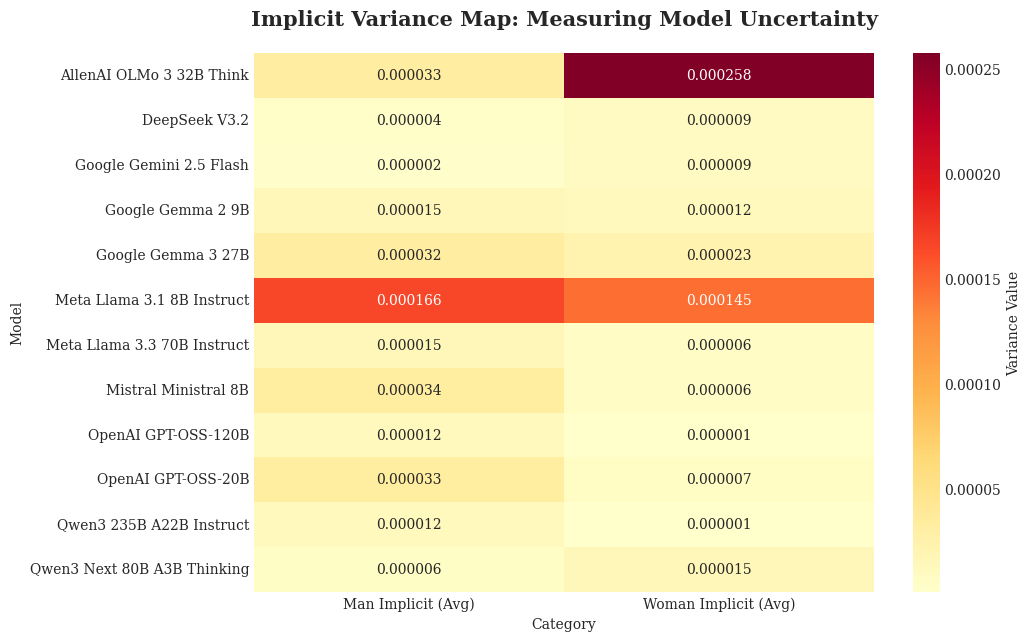

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 7))
df_var_imp = df_std_imp ** 2

sns.heatmap(df_var_imp, annot=True, cmap='YlOrRd', fmt='.6f', cbar_kws={'label': 'Variance Value'})

plt.title('Implicit Variance Map: Measuring Model Uncertainty', fontsize=15, fontweight='bold', pad=20)
plt.show()

In [ ]:
# 1. Map size categories according to your list
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–30B)',
    'Google Gemma 3 27B': 'Medium (15B–30B)',
    'AllenAI OLMo 3 32B Think': 'Medium-Large (30B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Add size category info to df_stats
df_stats['Size_Category'] = df_stats['Model'].map(size_cat_map)

# 3. Filter only Implicit
df_imp_size = df_stats[df_stats['Category'].isin(['Man Implicit (Avg)', 'Woman Implicit (Avg)'])]

# 4. Order Size Categories (to sort the graph from small to large)
size_order = [
    'Small (7B–10B)', 'Medium (15B–30B)', 'Medium-Large (30B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]

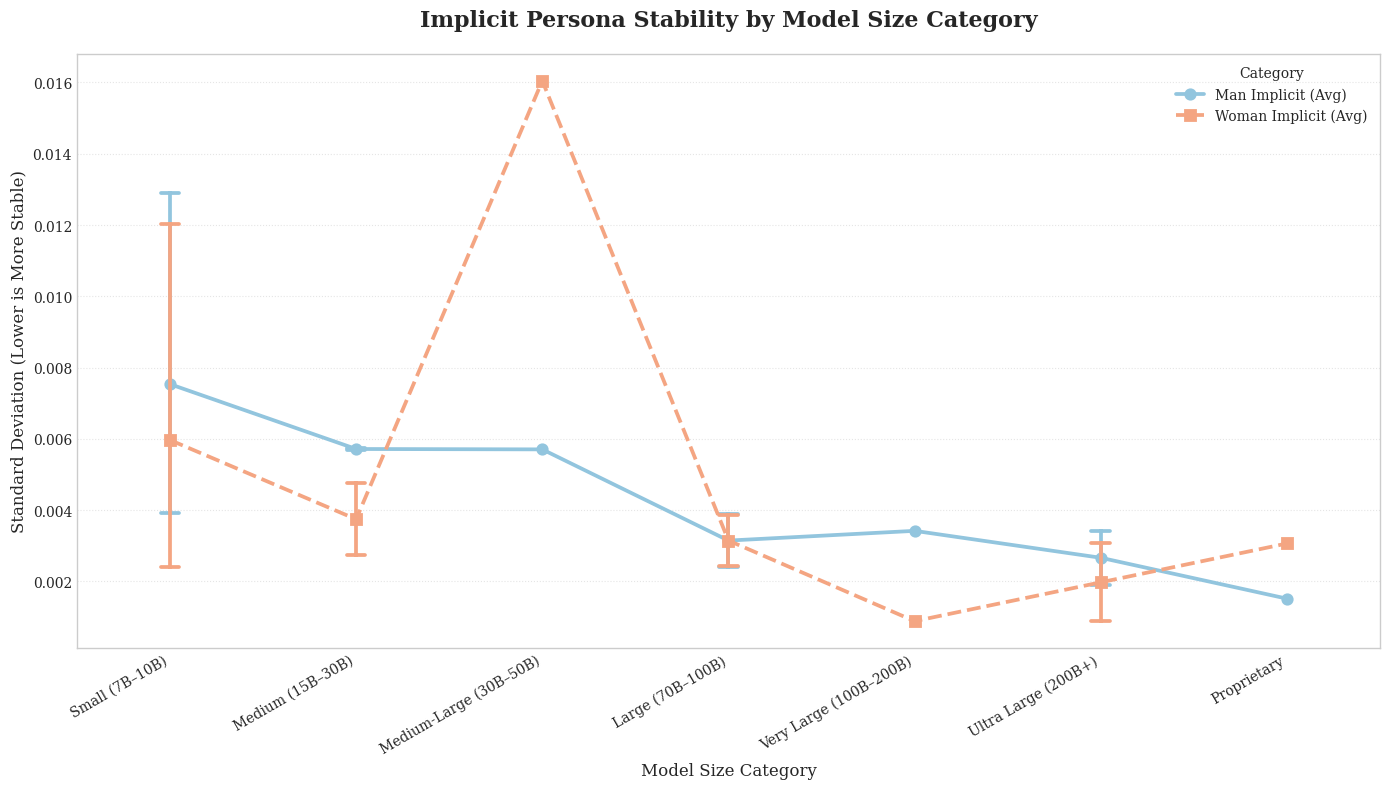

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
plt.rcParams['font.family'] = 'serif'

# Visualize Standard Deviation trend by size
sns.pointplot(
    data=df_imp_size,
    x='Size_Category', y='std', hue='Category',
    order=size_order, palette=['#92c5de', '#f4a582'],
    markers=["o", "s"], linestyles=["-", "--"], capsize=.1
)

plt.title('Implicit Persona Stability by Model Size Category', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Standard Deviation (Lower is More Stable)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

/tmp/ipykernel_707/1454413137.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_imp_size['variance'] = df_imp_size['std'] ** 2


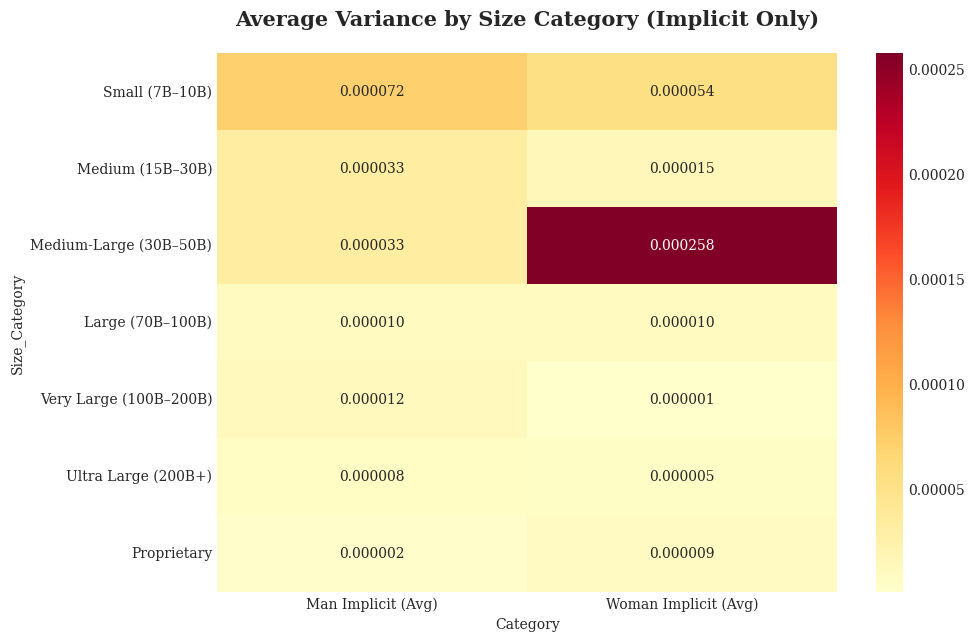

In [ ]:
# Calculate average variance (std^2) per size and per persona
df_imp_size['variance'] = df_imp_size['std'] ** 2
pivot_var_size = df_imp_size.groupby(['Size_Category', 'Category'])['variance'].mean().unstack()
pivot_var_size = pivot_var_size.reindex(size_order)

plt.figure(figsize=(10, 7))
sns.heatmap(pivot_var_size, annot=True, cmap='YlOrRd', fmt='.6f')

plt.title('Average Variance by Size Category (Implicit Only)', fontsize=15, fontweight='bold', pad=20)
plt.show()